In [1]:
import numpy as np
import matplotlib
from matplotlib import pyplot as plot
from matplotlib import pyplot as pyplot
from matplotlib.font_manager import FontProperties
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA
import sklearn.metrics
from sklearn.metrics import explained_variance_score, mean_squared_error, r2_score # https://scikit-learn.org/stable/auto_examples/linear_model/plot_ols.html
import statsmodels.api as sm
import pandas
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import scipy as sp
from scipy.odr import *
import scipy.stats
import random
import operator
import os
import seaborn as sns
from mpl_toolkits.mplot3d import axes3d
from matplotlib.patches import Polygon
import matplotlib.colors as mcolors
from scipy.optimize import fsolve
import math

# For 3d plots. This import is necessary to have 3D plotting below
from mpl_toolkits.mplot3d import Axes3D

# For statistics. Requires statsmodels 5.0 or more
from statsmodels.formula.api import ols
from statsmodels.formula.api import wls
# Analysis of Variance (ANOVA) on linear models
from statsmodels.stats.anova import anova_lm

# Adapted from:
# https://www.datasciencecentral.com/profiles/blogs/linear-regression-in-python-use-of-numpy-scipy-and-statsmodels,
# https://realpython.com/linear-regression-in-python/#multiple-linear-regression

C:\Users\hapra\AppData\Local\Temp\ipykernel_29064\966189482.py:15: DeprecationWarning: `scipy.odr` is deprecated as of version 1.17.0 and will be removed in SciPy 1.19.0. Please use `https://pypi.org/project/odrpack/` instead.
  from scipy.odr import *


In [25]:
#from intersect import intersection

plt.rcParams['axes.facecolor']='white'
plt.rcParams['savefig.facecolor']='white'
plt.rcParams['axes.edgecolor']='black'
plt.rcParams['savefig.edgecolor']='black'
plt.rcParams['figure.constrained_layout.use'] = True

#plt.rcParams['axes.prop_cycle'] = cycler(color='okabe_ito')
#plt.rcParams['image.cmap'] = 'okabe_ito'

plt.style.use('tableau-colorblind10')
#plt.style.use('okabe_ito')
okabe_ito_list = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']
tab_colorblind10_list = ['#006BA4', '#FF800E', '#ABABAB', '#595959',
                 '#5F9ED1', '#C85200', '#898989', '#A2C8EC', '#FFBC79', '#CFCFCF']
color_style_list = tab_colorblind10_list

# Article
#SMALLER_SIZE = 10
#SMALL_SIZE = 10
#MEDIUM_SIZE = 12
#BIGGER_SIZE = 14

#SMALLER_SIZE = 11
#SMALL_SIZE = 11
#MEDIUM_SIZE = 14
#BIGGER_SIZE = 16

# Presentation
SMALLER_SIZE = 12
SMALL_SIZE = 14
MEDIUM_SIZE = 18
BIGGER_SIZE = 24

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=BIGGER_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALLER_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [3]:
dataTypeList = ('|S12', '|S12', '|S12', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'unicode', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float', 'float')
# print (len(dataTypeList))
RawData = np.asarray(np.genfromtxt('lmc_observed_variables_rename_class_name_to_IDNum.csv',delimiter=';',skip_header=1))
# In this file, I renamed the assigned photometric and GRAMS model classes. 'o'->0; 'c' -> 1, 'x'->2,'s'->3

In [4]:
# Labels: Name	Cl	GCl	chi2	dM/dt	e_dM/dt	Lbol	e_Lbol	Teff	e_Teff	tau	e_tau	Amp	Per	SED	FU	e_FU	FB	e_FB	FV	e_FV	FI	e_FI	FJ	e_FJ	FH	e_FH	FK	e_FK	F3.6	e_F3.6	F4.5	e_F4.5	F5.8	e_F5.8	F8.0	e_F8.0	F24	e_F24	_RA	_DE
# This means that L_bol is at index 6 and period is at index 13
# FJ is at index 23, FK is at index 27, F3.6 is at 29

In [5]:
def mag3Point6Micron (input_array): # Take the flux in the 3.6 micron band in Jansky and return a magnitude
    mag = -2.5*np.log10(input_array/280.9) # Reference flux: 280.9±4.1
    return mag
def mag4Point5Micron (input_array):
    mag = -2.5*np.log10(input_array/179.7) # Reference flux: 179.7±2.6
    return mag
def mag5Point8Micron (input_array):
    mag = -2.5*np.log10(input_array/115.0) # Reference Flux: 115.0±1.7
    return mag
def mag8Point0Micron (input_array):
    mag = -2.5*np.log10(input_array/64.9) # Reference Flux: 64.9±0.9
    return mag

In [6]:
def multi_contour_plot (star_data_list,label_list = [], x_axis_ind = 0, y_axis_ind = 1, x_label = 'x', y_label = 'y',
                        cmap_list = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens, plt.cm.Reds],
                        color_list = ['tab:blue','tab:orange','tab:green','tab:red'], apply_log10_transform_x = True,
                        apply_mag_36_transformation_y = False, invert_x = False, invert_y = False,
                        save_figs = False):
    
    fig, ax = plt.subplots()
    handles, labels  = plt.gca().get_legend_handles_labels()
    for i in range(0, len(star_data_list)):
        star_data = star_data_list[i]
        xData = star_data[x_axis_ind]
        x_min = np.nanmin(xData)
        x_max = np.nanmax(xData)
        if apply_log10_transform_x == True:
            xData = np.log10(xData)
            x_min = np.nanmin(xData)
            x_max = np.nanmax(xData)
        yData = star_data[y_axis_ind]
        y_min = np.nanmin(yData)
        y_max = np.nanmax(yData)
        if apply_mag_36_transformation_y == True:
            yData = mag3Point6Micron(yData)
            y_min = np.nanmin(yData)
            y_max = np.nanmax(yData)
            
        # NaN clean
        x_data_nan = np.argwhere(np.isnan(xData))
        y_data_nan = np.argwhere(np.isnan(yData))
        nan_locations = np.unique(np.concatenate((x_data_nan,y_data_nan)))
        xData = np.delete(xData,nan_locations)
        yData = np.delete(yData,nan_locations)
        
        contour_x, contour_y = np.mgrid[x_min:x_max:100j, y_min:y_max:100j]
        positions = np.vstack([contour_x.ravel(), contour_y.ravel()])
        values = np.vstack([xData, yData])
        kernel = sp.stats.gaussian_kde(values)
        Z = np.reshape(kernel(positions).T, contour_x.shape)
        plot.contour(contour_x, contour_y, Z,cmap=cmap_list[i])
        
    lines = [plt.Line2D([0],[0],color = c, linewidth = 2, linestyle='-') for c in color_list]
    plot.legend(lines, label_list)
    
    plot.xlabel(x_label)
    plot.ylabel(y_label)
    
    if invert_x == True:
        fig.invert_xaxis()
    
    if invert_y == True:
        fig.invert_yaxis()
        
    if save_figs == True:
        name = x_label+y_label+'_'+'contour'
        for i in range(0, len(label_list)):
            name = name + '_'+label_list[i]
        plot.savefig(name+'.pdf')
        plot.savefig(name+'.png')
    plot.show()
    plot.close()

In [7]:
slopeLeft = (np.log10(5.60*10**-2)-np.log10(4.86*10**-3))/(np.log10(321.34)-np.log10(80.55)) # Use observational points to fit a
# slope to the left of sequence 1 (see Riebel et al. 2010) for Riebel et al. 2012 data
slopeRight = (np.log10(4.72*10**-2)-np.log10(2.94*10**-3))/(np.log10(531.35)-np.log10(133.64)) # Do the same but on the right side
meanSlope = (slopeLeft+slopeRight)/2 # Determine an average slope from the data above

def seq1LeftCut (input_array):
    i = 0
    slope = slopeLeft
    CuttingArray = [] # List of rows to be cut. Starts empty and gets filled by while loop
    while i<len(input_array): # As long as our index is less than the length of our input data
    #while i<5:
        CuttingF = slope*(np.log10(input_array[i][13])-np.log10(321.34))+np.log10(5.60*10**-2) # Establish the cutting line
        if CuttingF <= np.log10(input_array[i][29]) : # If the actual flux is lower than the value found from the cutting line
            CuttingArray.append(i)
        i += 1 # Increment i to the next index
    print('Sequence 2, 3, and 4 stars cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

def seq1RightCut (input_array):
    i = 0
    slope = slopeRight
    CuttingArray = [] # List of rows to be cut. Starts empty and gets filled by while loop
    while i<len(input_array): # As long as our index is less than the length of our input data
    #while i<5:
        CuttingF = slope*(np.log10(input_array[i][13])-np.log10(531.35))+np.log10(4.72*10**-2) # Establish the cutting line
        if CuttingF >= np.log10(input_array[i][29]) : # If the actual flux is higher than the value found from the cutting line
            CuttingArray.append(i)
        i += 1 # Increment i to the next index
    print('Sequence D and E stars cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

slope3Left = (np.log10(5.97*10**-2)-np.log10(5.86*10**-3))/(np.log10(163.72)-np.log10(41.31)) # Use observational points to fit a slope to the left of sequence 1 (see Riebel et al. 2010) for Riebel et al. 2012 data
slope2Left = (np.log10(2.70*10**-2)-np.log10(4.68*10**-3))/(np.log10(131.98)-np.log10(50.52)) # Use observational points to fit a slope to the left of sequence 1 (see Riebel et al. 2010) for Riebel et al. 2012 data
slope2Right = (np.log10(0.12)-np.log10(0.004801529852119834))/(np.log10(374.40)-np.log10(80)) # Do the same but on the right side
meanSlope2 = (slope2Left+slope2Right)/2 # Determine an average slope from the data above
# Point 1: pyplot.plot(np.log10(120),mag3Point6Micron(10**(slope2Left*(np.log10(120)-np.log10(131.98))+np.log10(2.70*10**-2))),c='blue',marker='o',linestyle='--',ms=3)
# Point 2: pyplot.plot(np.log10(160),mag3Point6Micron(10**(slope3Left*(np.log10(160)-np.log10(163.72))+np.log10(5.97*10**-2))),c='blue',marker='o',linestyle='--',ms=3)
slope2Left_Part2 = ((slope3Left*(np.log10(200)-np.log10(163.72))+np.log10(5.97*10**-2))-(slope2Left*(np.log10(120)-np.log10(131.98))+np.log10(2.70*10**-2)))/(np.log10(200)-np.log10(120))
# This slope uses constructed points. In the end, it is effectively made between two points (120, 2.27*10^-2) and (200, 8.37*10^-2)
def mag3Point6MicronToFlux3Point6 (mag):
    flux =  280.9*(10**(mag/(-2.5)))
    return flux


def seq2LeftCut (input_array):
    i = 0
    #slope = slope2Left
    CuttingArray = [] # List of rows to be cut. Starts empty and gets filled by while loop
    while i<len(input_array): # As long as our index is less than the length of our input data
    #while i<5:
        if input_array[i][13] < 120:
            slope = slope2Left
            logP=np.log10(input_array[i][13])
            logP0=np.log10(131.98)
            logF0=np.log10(2.70*10**-2)
            CuttingF = slope*(logP-logP0)+logF0 # Establish the cutting line
            if CuttingF <= np.log10(input_array[i][29]) : # If the actual flux is lower than the value found from the cutting line
                CuttingArray.append(i)
        else:
            slope = slope2Left_Part2
            logP=np.log10(input_array[i][13])
            logP0=np.log10(120)
            logF0=np.log10(mag3Point6MicronToFlux3Point6(mag3Point6Micron(10**(slope2Left*(np.log10(120)-np.log10(131.98))+np.log10(2.70*10**-2)))))
            CuttingF = slope*(logP-logP0)+logF0 # Establish the cutting line
            if CuttingF <= np.log10(input_array[i][29]) : # If the actual flux is lower than the value found from the cutting line
                CuttingArray.append(i)
        i += 1 # Increment i to the next index
    print('Sequence 3, and 4 stars cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

def seq2RightCut (input_array):
    i = 0
    slope = slope2Right
    CuttingArray = [] # List of rows to be cut. Starts empty and gets filled by while loop
    while i<len(input_array): # As long as our index is less than the length of our input data
    #while i<5:
        CuttingF = slope*(np.log10(input_array[i][13])-np.log10(374.40))+np.log10(0.12) # Establish the cutting line
        if CuttingF >= np.log10(input_array[i][29]) : # If the actual flux is higher than the value found from the cutting line
            CuttingArray.append(i)
        i += 1 # Increment i to the next index
    print('Sequence 1, D, and E stars cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array



slope3Left = (np.log10(5.97*10**-2)-np.log10(5.86*10**-3))/(np.log10(163.72)-np.log10(41.31)) # Use observational points to fit a slope to the left of sequence 1 (see Riebel et al. 2010) for Riebel et al. 2012 data
slope3Right = (np.log10(2.70*10**-2)-np.log10(4.68*10**-3))/(np.log10(131.98)-np.log10(50.52)) # Do the same but on the right side
meanSlope3 = (slope3Left+slope3Right)/2 # Determine an average slope from the data above

def seq3LeftCut (input_array):
    i = 0
    slope = slope3Left
    CuttingArray = [] # List of rows to be cut. Starts empty and gets filled by while loop
    while i<len(input_array): # As long as our index is less than the length of our input data
    #while i<5:
        CuttingF = slope*(np.log10(input_array[i][13])-np.log10(113.75))+np.log10(4.16*10**-2) # Establish the cutting line
        if CuttingF <= np.log10(input_array[i][29]) : # If the actual flux is lower than the value found from the cutting line
            CuttingArray.append(i)
        i += 1 # Increment i to the next index
    print('Sequence 4 stars cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

def seq3RightCut (input_array):
    i = 0
    slope = slope3Right
    CuttingArray = [] # List of rows to be cut. Starts empty and gets filled by while loop
    while i<len(input_array): # As long as our index is less than the length of our input data
    #while i<5:
        if input_array[i][13] < 120:
            CuttingF = slope*(np.log10(input_array[i][13])-np.log10(131.98))+np.log10(2.70*10**-2) # Establish the cutting line
            if CuttingF >= np.log10(input_array[i][29]) : # If the actual flux is greater than the value found from the cutting line
                CuttingArray.append(i)
        else:
            slope = slope2Left_Part2
            logP=np.log10(input_array[i][13])
            logP0=np.log10(120)
            logF0=np.log10(mag3Point6MicronToFlux3Point6(mag3Point6Micron(10**(slope2Left*(np.log10(120)-np.log10(131.98))+np.log10(2.70*10**-2)))))
            CuttingF = slope*(logP-logP0)+logF0 # Establish the cutting line
            if CuttingF >= np.log10(input_array[i][29]) : # If the actual flux is greater than the value found from the cutting line
                CuttingArray.append(i)
            
        i += 1 # Increment i to the next index
    print('Sequence 3, and 4 stars cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array
    print('Sequence 1, 2, D, and E stars cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

#M0Max = 2.15 # The maximum initial mass represented by computed values
M0Max = 10.0
def LuminosityCut (input_array): # Use a CMLR and IFMR (in this case I and T and Zhao et al.) to find a cut-off luminosity for Miras
    i = 0
    CuttingArray = []
    while i<len(input_array):
        FinalM = 0.452+0.073*M0Max
        CuttingL = (6.34*10**4)*(FinalM-0.44)*(FinalM/7)**0.19
        if CuttingL <= input_array[i][6]: # if the luminosity is greater than the highest final luminosity we assumed
            CuttingArray.append(i)
        i+=1
    print('Stars above maximum L cut:', len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

def MassCut (input_array,Z,alpha): # Takes the Riebel data array, a metallcity input, and a mixing length input.
    i = 0
    CuttingArray=[]
    while i<len(input_array):
        L = input_array[i][6]
        P = input_array[i][13]
        #logM = -1.5973-0.765345*np.log10(input_array[i][13]) +0.968009*np.log10(input_array[i][6]) + 0.125272*np.log10(Z/0.0124)- 0.740242*np.log10(alpha)
        logM = -3.20556+1.7326*np.log10(L)-1.36986*np.log10(P)+0.224219*np.log10(Z/0.001)-1.32493*np.log10(alpha)
        if 10**(logM) >= 2.15:
            CuttingArray.append(i)
        i += 1
    print('Stars above 2.15 Solar Masses Cut:',len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

def Magnitude_cut (input_array):
    i = 0
    CuttingArray =[]
    while i<len(input_array):
        if np.isnan(input_array[i][29])==True:
            CuttingArray.append(i)
            print ('NaN at i=',i)
        elif mag3Point6Micron (input_array[i][29]) < 10.3:
            CuttingArray.append(i)
        i += 1
    print ('Stars below [3.6]=10.3 or unknown [3.6] Cut:', len(CuttingArray))
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array
        
def Magnitude_cut_inverse (input_array):
    i = 0
    CuttingArray =[]
    while i<len(input_array):
        if np.isnan(input_array[i][29])==True:
            CuttingArray.append(i)
        elif mag3Point6Micron (input_array[i][29]) > 10.3:
            CuttingArray.append(i)
        i += 1
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

def Period_cut (input_array):
    i = 0
    CuttingArray=[]
    while i<len(input_array):
        if input_array[i][13]<80:
            CuttingArray.append(i)
        i += 1
    Modified_Array = np.delete(input_array,CuttingArray,axis=0)
    return Modified_Array

In [8]:
def Calculate3Point6Minus4Point5Color (input_array):
    mag36 = -2.5*np.log10(input_array[29]/280.9) # Reference flux: 280.9±4.1
    mag45 = -2.5*np.log10(input_array[31]/179.7) # Reference flux: 179.7±2.6
    Color = mag36-mag45
    return Color

def Calculate5Point8Minus8Point0Color (input_array):
    mag58 = -2.5*np.log10(input_array[33]/115.0) # Reference Flux: 115.0±1.7
    mag80 = -2.5*np.log10(input_array[35]/64.9) # Reference Flux: 64.9±0.9
    Color = mag58-mag80
    return Color

In [9]:
def CarbonStarSort(input_array):
    i = 0
    ListofCStars =[]
    while i<len(input_array):
        if input_array[i][2] == 1:
            ListofCStars.append(input_array[i])
        i+=1
    print ('Carbon stars found:',len(ListofCStars))
    return ListofCStars
def NonCarbonStarSort(input_array):
    i = 0
    ListofNotCStars =[]
    while i<len(input_array):
        if input_array[i][2] != 1:
            ListofNotCStars.append(input_array[i])
        i+=1
    print ('M stars found:',len(ListofNotCStars))
    return ListofNotCStars
print(len(RawData), len(CarbonStarSort(RawData)), len(NonCarbonStarSort(RawData)))

Carbon stars found: 3409
M stars found: 11679
15088 3409 11679


In [10]:
FinalM = 0.452+0.073*M0Max
(6.34*10**4)*(FinalM-0.44)*(FinalM/7)**0.19

33552.26599309993

(array([  3.,  20.,  87., 138., 175., 214., 224., 259., 260., 258., 285.,
        325., 367., 333., 313., 329., 348., 361., 375., 405., 388., 367.,
        370., 336., 320., 326., 294., 284., 323., 345., 251., 300., 254.,
        253., 236., 339., 350., 211., 221., 337., 277., 306., 343., 365.,
        354., 432., 439., 525., 410., 453.]),
 array([1.39842615, 1.42903471, 1.45964328, 1.49025185, 1.52086041,
        1.55146898, 1.58207755, 1.61268611, 1.64329468, 1.67390325,
        1.70451181, 1.73512038, 1.76572895, 1.79633751, 1.82694608,
        1.85755465, 1.88816322, 1.91877178, 1.94938035, 1.97998892,
        2.01059748, 2.04120605, 2.07181462, 2.10242318, 2.13303175,
        2.16364032, 2.19424888, 2.22485745, 2.25546602, 2.28607458,
        2.31668315, 2.34729172, 2.37790028, 2.40850885, 2.43911742,
        2.46972598, 2.50033455, 2.53094312, 2.56155169, 2.59216025,
        2.62276882, 2.65337739, 2.68398595, 2.71459452, 2.74520309,
        2.77581165, 2.80642022, 2.83702879, 2.

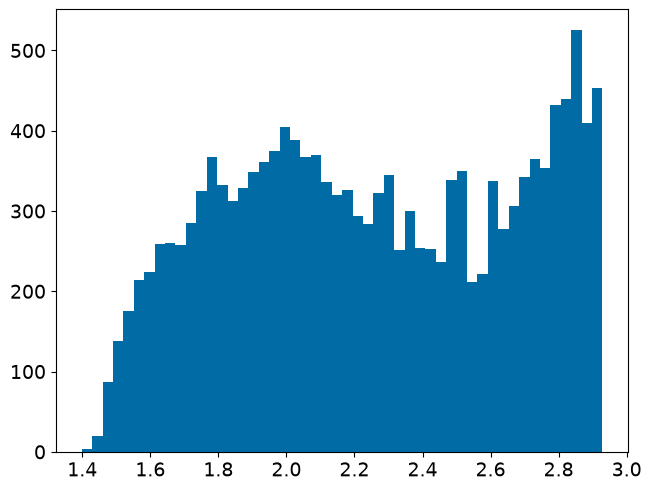

In [11]:
pyplot.hist(np.log10(np.transpose(RawData)[13]),bins=50)

In [12]:
#CutData = np.asarray(RVTauCut(SRVCut(CepheidCut(RawData))))
CutData= np.asarray(seq1LeftCut(seq1RightCut((RawData))))
Seq2CutData = np.asarray(seq2LeftCut(seq2RightCut(RawData)))
Seq3CutData = np.asarray(seq3LeftCut(seq3RightCut(RawData)))
#CutData = np.asarray(LuminosityCut(CutData))
CarbonStars = np.asarray(CarbonStarSort(CutData))
NonCarbonStars = np.asarray(NonCarbonStarSort(CutData))
CarbonStarsSeq2 = np.asarray(CarbonStarSort(Seq2CutData))
NonCarbonStarsSeq2 = np.asarray(NonCarbonStarSort(Seq2CutData))
CarbonStarsSeq3 = np.asarray(CarbonStarSort(Seq3CutData))
NonCarbonStarsSeq3 = np.asarray(NonCarbonStarSort(Seq3CutData))
CutData = np.asarray(LuminosityCut(CutData))
CutData = np.asarray(Magnitude_cut(CutData))
CutDatatoSave=np.asarray(NonCarbonStarSort(CutData))
print('Mira Candidates remaining:',len(CutData))
np.savetxt('CleanedData_MiraData.csv',CutDatatoSave,delimiter=';')
np.savetxt('CleanedData_CarbonStarData.csv',CarbonStars,delimiter=';')
np.savetxt('CleanedData_MStarData_Seq2.csv',NonCarbonStarsSeq2,delimiter=';')
np.savetxt('CleanedData_CarbonStarData_Seq2.csv',CarbonStarsSeq2,delimiter=';')
np.savetxt('CleanedData_MStarData_Seq3.csv',NonCarbonStarsSeq3,delimiter=';')
np.savetxt('CleanedData_CarbonStarData_Seq3.csv',CarbonStarsSeq3,delimiter=';')
print('M-type Miras remaining:',len(NonCarbonStars))

Sequence D and E stars cut: 3864
Sequence 2, 3, and 4 stars cut: 6727
Sequence 1, D, and E stars cut: 8429
Sequence 3, and 4 stars cut: 3059
Sequence 3, and 4 stars cut: 10696
Sequence 4 stars cut: 1341
Carbon stars found: 2069
M stars found: 2428
Carbon stars found: 839
M stars found: 2761
Carbon stars found: 95
M stars found: 2956
Stars above maximum L cut: 11
NaN at i= 155
NaN at i= 156
NaN at i= 157
NaN at i= 158
NaN at i= 382
NaN at i= 429
NaN at i= 514
NaN at i= 576
NaN at i= 629
NaN at i= 630
NaN at i= 642
NaN at i= 679
NaN at i= 898
NaN at i= 1170
NaN at i= 1172
NaN at i= 1173
NaN at i= 1180
NaN at i= 1193
NaN at i= 1225
NaN at i= 1260
NaN at i= 1261
NaN at i= 1317
NaN at i= 1388
NaN at i= 1396
NaN at i= 1426
NaN at i= 1757
NaN at i= 2021
NaN at i= 2035
NaN at i= 2043
NaN at i= 2205
NaN at i= 2206
NaN at i= 2207
NaN at i= 2254
NaN at i= 2258
NaN at i= 2323
NaN at i= 2330
NaN at i= 2338
NaN at i= 2682
NaN at i= 2698
NaN at i= 2705
NaN at i= 3214
NaN at i= 3386
NaN at i= 3507
NaN

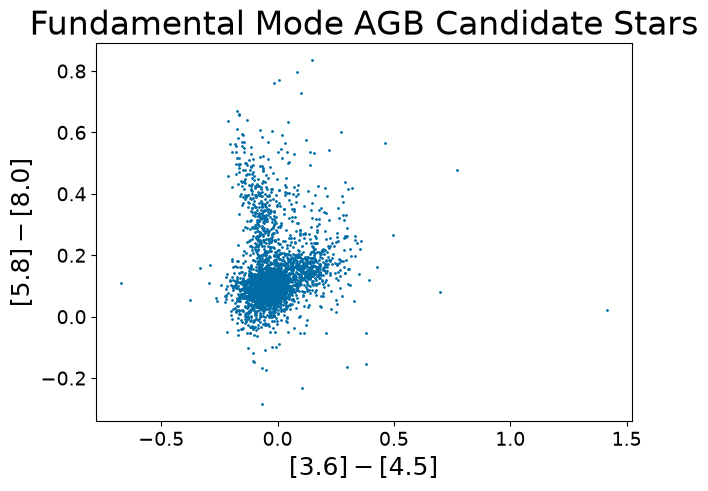

In [27]:
Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(CutData))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(CutData))

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = plot.xlabel(r'$[3.6]-[4.5]$')
#PxlabelText.set_fontsize(8) 
PylabelText = plot.ylabel(r'$[5.8]-[8.0]$')
#PylabelText.set_fontsize(8) 
plot.title('Fundamental Mode AGB Candidate Stars')

plot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.')

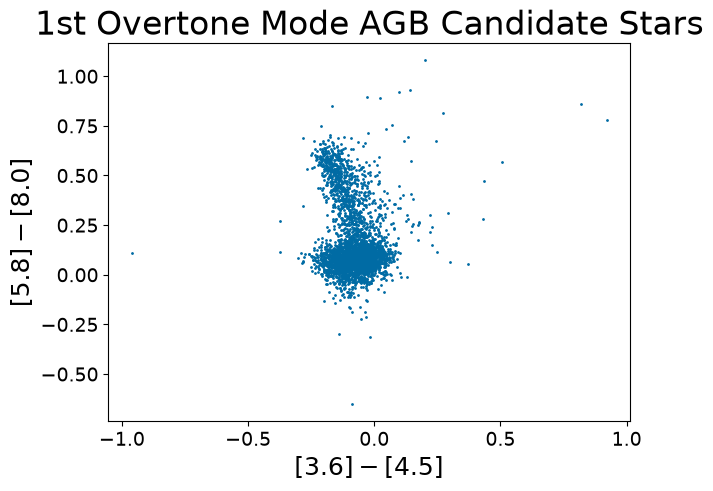

In [28]:
Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(Seq2CutData))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(Seq2CutData))

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[4.5]$')
#PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[5.8]-[8.0]$')
#PylabelText.set_fontsize(8) 
pyplot.title('1st Overtone Mode AGB Candidate Stars')

pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.')

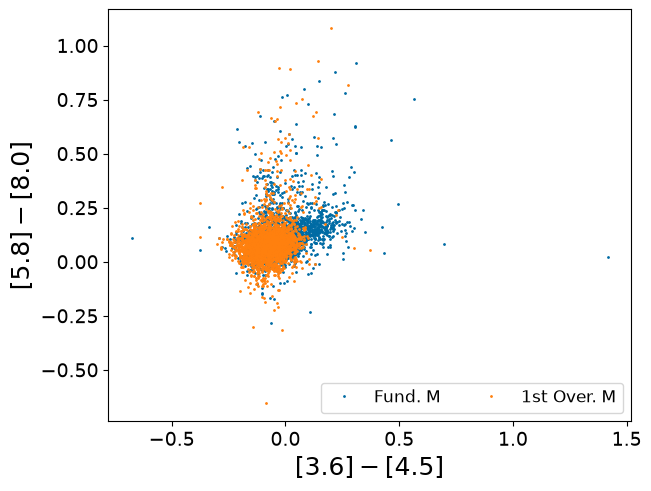

In [30]:
Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(NonCarbonStars))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(NonCarbonStars))
plot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.',label='Fund. M')

Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(NonCarbonStarsSeq2))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(NonCarbonStarsSeq2))

plot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.',label='1st Over. M')

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = plot.xlabel(r'$[3.6]-[4.5]$')
#PxlabelText.set_fontsize(8) 
PylabelText = plot.ylabel(r'$[5.8]-[8.0]$')
#PylabelText.set_fontsize(8) 
#pyplot.title('1st Overtone Mode C-Stars')
plot.legend(loc='lower right',ncol=2)


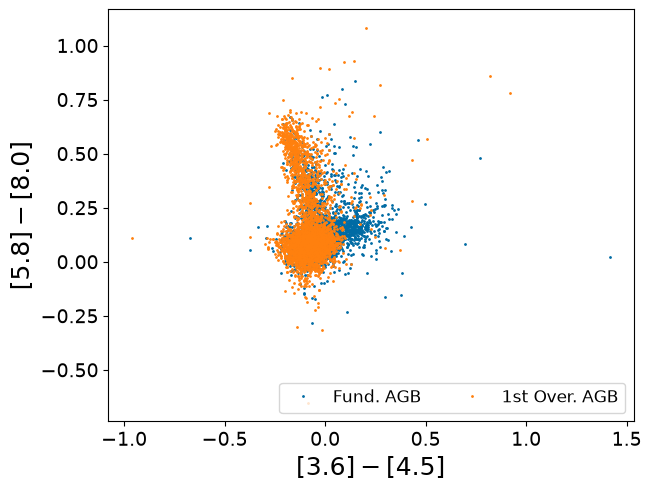

In [31]:
Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(CutData))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(CutData))
pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.',label='Fund. AGB')

Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(Seq2CutData))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(Seq2CutData))

pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.',label='1st Over. AGB')

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[4.5]$')
#PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[5.8]-[8.0]$')
#PylabelText.set_fontsize(8) 
#pyplot.title('1st Overtone Mode C-Stars')
pyplot.legend(loc='lower right',ncol=2)


Text(0.5, 1.0, 'Fundamental Mode C-Stars')

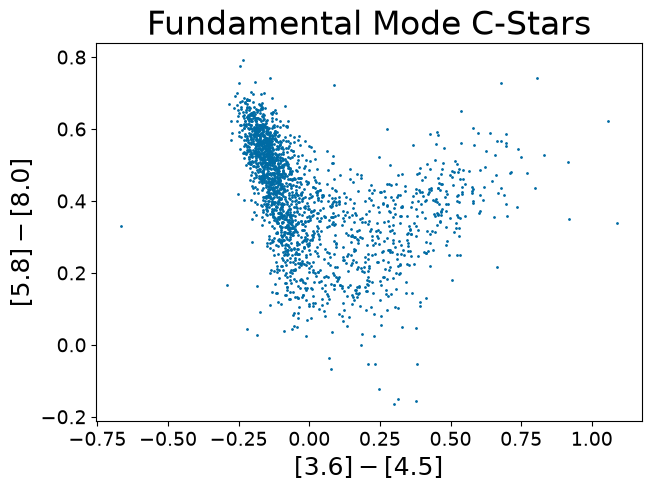

In [32]:
Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(CarbonStars))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(CarbonStars))
pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.')

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[4.5]$')
#PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[5.8]-[8.0]$')
#PylabelText.set_fontsize(8) 
pyplot.title('Fundamental Mode C-Stars')


In [33]:
def CarbonStarColorSort (input_array):
    SRVList =[]
    MiraList =[]
    Colors = Calculate3Point6Minus4Point5Color(input_array)
    while i < len(input_array[0]):
        if Color[i] <= 0:
            SRVList.append(i)
        else:
            MiraList.append(i)
        i+=1
    SRV_Array = np.delete(input_array,MiraList,axis=0)
    Mira_Array = np.delete(input_array,SRVList,axis=0)
    return SRV_Array,Mira_Array

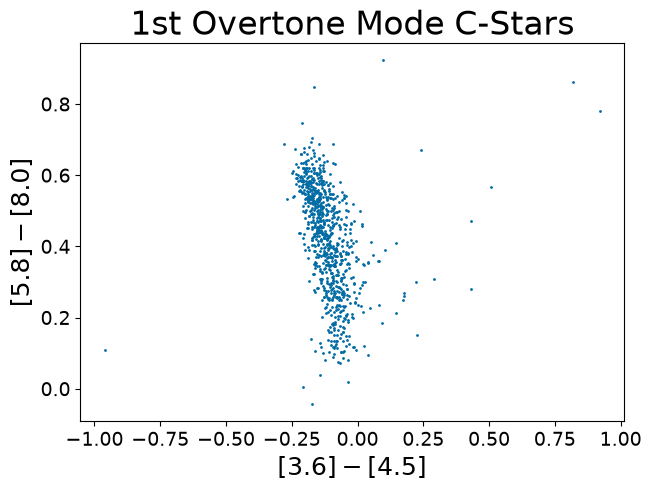

In [35]:
Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(CarbonStarsSeq2))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(CarbonStarsSeq2))

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[4.5]$')
#PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[5.8]-[8.0]$')
#PylabelText.set_fontsize(8) 
pyplot.title('1st Overtone Mode C-Stars')

pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.')

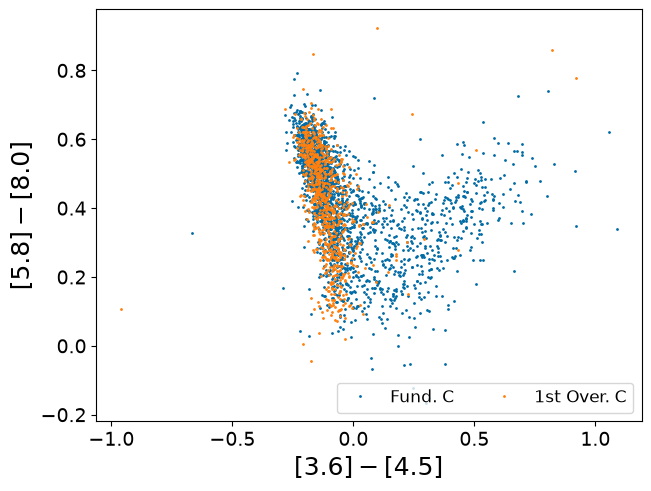

In [37]:
Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(CarbonStars))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(CarbonStars))
pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.',label='Fund. C')

Color3Point6Minus4Point5 = Calculate3Point6Minus4Point5Color(np.transpose(CarbonStarsSeq2))
Color5Point8Minus8Point0 = Calculate5Point8Minus8Point0Color(np.transpose(CarbonStarsSeq2))

pyplot.plot(Color3Point6Minus4Point5,Color5Point8Minus8Point0,linestyle='',ms=2,marker='.',label='1st Over. C')

xlimits = [-0.5,1.5]
ylimits = [-0.2,1.2]

#pyplot.xlim(xlimits)
#pyplot.ylim(ylimits)

PxlabelText = pyplot.xlabel(r'$[3.6]-[4.5]$')
#PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[5.8]-[8.0]$')
#PylabelText.set_fontsize(8) 
#pyplot.title('1st Overtone Mode C-Stars')
pyplot.legend(loc='lower right',ncol=2)


In [22]:
testarray=[2,3,4,5,7,8]
testarray[1:3][0]

3

In [24]:
plottable_data_M = np.transpose(NonCarbonStarSort(RawData))
plottable_data_C = np.transpose(CarbonStarSort(RawData))

M stars found: 11679
Carbon stars found: 3409


M stars found: 11679
M stars found: 11679
Carbon stars found: 3409
Carbon stars found: 3409
0.004801529852119834 11.917930264733343


C:\Users\hapra\AppData\Local\Temp\ipykernel_29064\261525896.py:82: UserWarning: The figure layout has changed to tight
  RawDataWithCutsPlot.tight_layout()


File saved


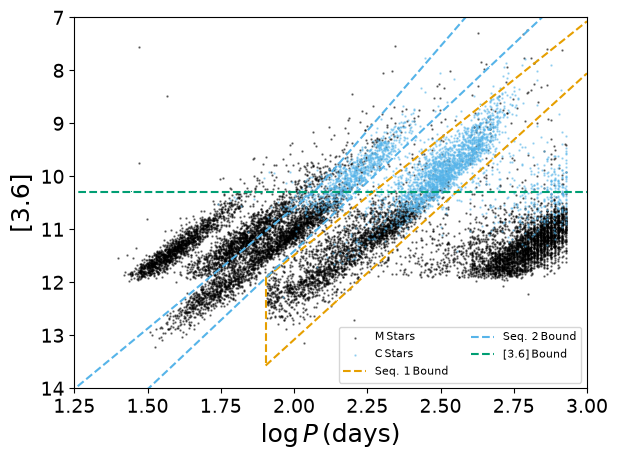

In [48]:
color_list = ['#000000','#e69f00','#56b4e9','#009e73','#f0e442', '#0072b2', '#d55e00', '#cc79a7'] # A color-blind friendly color scheme
marker_list = ['.','v','s','h']
RawDataWithCutsPlot = pyplot.figure()

pyplot.scatter(np.log10(np.transpose(NonCarbonStarSort(RawData))[13]),mag3Point6Micron(np.transpose(NonCarbonStarSort(RawData))[29]),c=color_list[0],marker=marker_list[0],linestyle='',s=2,label = r'$\mathrm{M\, Stars}$',alpha=0.5,rasterized=True)
pyplot.scatter(np.log10(np.transpose(CarbonStarSort(RawData))[13]),mag3Point6Micron(np.transpose(CarbonStarSort(RawData))[29]),c=color_list[2],marker=marker_list[0],linestyle='',s=2,label = r'$\mathrm{C\, Stars}$', alpha=0.5,rasterized=True)
#pyplot.plot(0,0,c=color_list[2],marker=marker_list[0],linestyle='',ms=1, label = r'$\mathrm{C\, Stars}$')
#pyplot.plot(np.log10(np.transpose(NonCarbonStarSort(CutData))[13]),mag3Point6Micron(np.transpose(NonCarbonStarSort(CutData))[29]),c=color_list[0],marker=marker_list[0],linestyle='',ms=1,alpha=1, label = r'$\mathrm{M\, Stars}$')
#pyplot.plot(np.log10(np.transpose(CarbonStarSort(CutData))[13]),np.log10(np.transpose(CarbonStarSort(CutData))[6]),c=color_list[7],marker=marker_list[0],linestyle='',ms=1,alpha=1, label = r'$\mathrm{C\, Stars}$')

logP=np.linspace(np.log10(80), 3, 10)
CutlineRight = mag3Point6Micron(10**(slopeRight*(logP-np.log10(531.35))+np.log10(4.72*10**-2)))
# apply function mag3Point6Micron
pyplot.plot(logP,CutlineRight,c=color_list[1],marker=',',linestyle='--',ms=1, label = r'$\mathrm{Seq.\, 1\, Bound}$')

CutlineLeft = mag3Point6Micron(10**(slopeLeft*(logP-np.log10(80.55))+np.log10(4.86*10**-3)))
pyplot.plot(logP,CutlineLeft,c=color_list[1],marker=',',linestyle='--',ms=1)

print(10**(slopeLeft*(logP-np.log10(80.55))+np.log10(4.86*10**-3))[0],CutlineLeft[0])

pyplot.vlines(np.log10(80),CutlineLeft[0],CutlineRight[0],colors=color_list[1],linestyles='--',)
#CutlineCeph = (np.log10(11839.00)-np.log10(2114.00))/(np.log10(91.81)-np.log10(38.78))*(logP-np.log10(38.78))+np.log10(2114.00)
#pyplot.plot(logP,CutlineCeph,c=color_list[3],marker=',',linestyle='-',ms=1, label = r'$\mathrm{Cepheid\, Cut}$')

#CutlineSRV = (np.log10(14822.00)-np.log10(2187.00))/(np.log10(769.82)-np.log10(295.07))*((logP)-np.log10(295.07))+np.log10(2187.00)
#pyplot.plot(logP,CutlineSRV,c=color_list[5],marker=',',linestyle='-',ms=1, label = r'$\mathrm{SRV\, Cut}$')

#CutlineRVTau = (np.log10(12760.00)-np.log10(1820.00))/(np.log10(336.70)-np.log10(67.37))*((logP)-np.log10(67.37))+np.log10(1820.00)
#pyplot.plot(logP,CutlineRVTau,c=color_list[6],marker=',',linestyle='-',ms=1, label = r'$\mathrm{RV\, Tauri\, Cut}$')


logP=np.linspace(np.log10(1), 3, 10)
CutlineRight = mag3Point6Micron(10**(slope2Right*(logP-np.log10(374.40))+np.log10(0.12)))
pyplot.plot(logP,CutlineRight,c=color_list[2],marker=',',linestyle='--',ms=1, label = r'$\mathrm{Seq.\, 2\, Bound}$')

#CutlineLeft = mag3Point6Micron(10**(slope2Left*(logP-np.log10(131.98))+np.log10(2.70*10**-2)))
#pyplot.plot(logP,CutlineLeft,c=color_list[2],marker=',',linestyle='--',ms=1)

'''

            slope = slope2Left_Part2
            logP=np.log10(input_array[i][13])
            logP0=np.log10(120)
            logF0=np.log10(mag3Point6MicronToFlux3Point6(mag3Point6Micron(10**(slope2Left*(np.log10(120)-np.log10(131.98))+np.log10(2.70*10**-2)))))
            CuttingF = slope*(logP-logP0)+logF0 # Establish the cutting line
''' 


logP_range1=np.linspace(1, np.log10(120), 10)
logP_range2=np.linspace(np.log10(120), 3, 10)
CutlineRight = mag3Point6Micron(10**(slope3Right*(logP_range1-np.log10(131.98))+np.log10(2.70*10**-2)))
pyplot.plot(logP_range1,CutlineRight,c=color_list[2],marker=',',linestyle='--',ms=1)

CutlineRight = mag3Point6Micron(10**(slope2Left_Part2*(logP_range2-np.log10(120))+np.log10(mag3Point6MicronToFlux3Point6(mag3Point6Micron(10**(slope2Left*(np.log10(120)-np.log10(131.98))+np.log10(2.70*10**-2)))))))
#CutlineRight = 
pyplot.plot(logP_range2,CutlineRight,c=color_list[2],marker=',',linestyle='--',ms=1)
#pyplot.plot(np.log10(120),mag3Point6Micron(10**(slope2Left*(np.log10(120)-np.log10(131.98))+np.log10(2.70*10**-2))),c='blue',marker='o',linestyle='--',ms=3)

logP_range3=np.linspace(1, np.log10(200), 10)
CutlineLeft = mag3Point6Micron(10**(slope3Left*(logP_range3-np.log10(163.72))+np.log10(5.97*10**-2)))
#pyplot.plot(logP_range3,CutlineLeft,c=color_list[4],marker=',',linestyle='--',ms=1)
#pyplot.plot(np.log10(200),mag3Point6Micron(10**(slope3Left*(np.log10(200)-np.log10(163.72))+np.log10(5.97*10**-2))),c='blue',marker='o',linestyle='--',ms=3)



logP=np.linspace(1,3,10)
CutlineMagBound = 10.3*np.ones(10)
pyplot.plot(logP,CutlineMagBound,c=color_list[3],marker=',',linestyle='--',ms=1,label = r'$\mathrm{[3.6]\, Bound}$')
xlimits = [1.25,3]
ylimits = [14,7]

pyplot.xlim([1.25,3.])
pyplot.ylim([14.,7.])
#pyplot.text(xlimits[0], ylimits[0]-0.01*(ylimits[0]-ylimits[1]),'(a)')
    
PxlabelText = pyplot.xlabel(r'$\log P\, \mathrm{(days)}$')
#PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]$')
#PylabelText.set_fontsize(8) 
pyplot.legend(loc='lower right',ncol=2,fontsize='xx-small')
pyplot.ticklabel_format(style='plain', axis='both', scilimits=(0,0))
RawDataWithCutsPlot.tight_layout()
RawDataWithCutsPlot.savefig('RawDataWithCutsPlot.png',format='png')
RawDataWithCutsPlot.savefig('RawDataWithCutsPlot.pdf',format='pdf')
print ('File saved')
pyplot.show()
pyplot.close(RawDataWithCutsPlot)

In [62]:
CutDatatoSave

array([[ 2.900000e+01,  0.000000e+00,  0.000000e+00, ...,           nan,
         7.974146e+01, -6.823417e+01],
       [ 3.600000e+01,  0.000000e+00,  0.000000e+00, ...,  5.327000e-05,
         8.130525e+01, -6.771825e+01],
       [ 5.300000e+01,  0.000000e+00,  0.000000e+00, ...,           nan,
         7.678692e+01, -6.953819e+01],
       ...,
       [ 1.167600e+04,  3.000000e+00,  0.000000e+00, ...,           nan,
         7.379229e+01, -7.008583e+01],
       [ 1.167700e+04,  3.000000e+00,  0.000000e+00, ...,           nan,
         7.544517e+01, -6.770578e+01],
       [ 1.167800e+04,  3.000000e+00,  0.000000e+00, ...,           nan,
         7.731350e+01, -6.873203e+01]])

In [63]:
MStars_1 = np.transpose(CutDatatoSave)
CStars_1 = np.transpose(CarbonStars)
MStars_2 = np.transpose(NonCarbonStarsSeq2)
CStars_2 = np.transpose(CarbonStarsSeq2)
MStars_3 = np.transpose(NonCarbonStarsSeq3)
CStars_3 = np.transpose(CarbonStarsSeq3)

IndexError: list index out of range

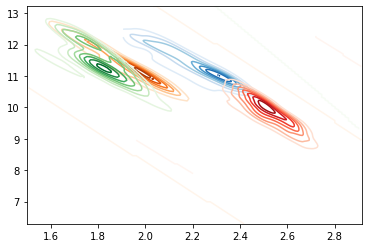

In [73]:
multi_contour_plot ([MStars_1,MStars_2,MStars_3,CStars_1,CStars_2, CStars_3],label_list = ['M0 Stars','M1 Stars','C0 Stars','C1 Stars'], x_axis_ind = 13, y_axis_ind = 29, x_label = r'$\log P$', y_label = r'$[3.6]$',
                        cmap_list = [plt.cm.Blues, plt.cm.Oranges, plt.cm.Greens, plt.cm.Reds],
                        color_list = ['tab:blue','tab:orange','tab:green','tab:red'], apply_log10_transform_x = True,
                        apply_mag_36_transformation_y = True, invert_y = True,
                        save_figs = False)

In [24]:
logP_range2-np.log10(120)

array([0.        , 0.10231319, 0.20462639, 0.30693958, 0.40925278,
       0.51156597, 0.61387917, 0.71619236, 0.81850556, 0.92081875])

In [25]:
RawDataWithCutsPlot = pyplot.figure()

pyplot.plot(np.log10(np.transpose(NonCarbonStarSort(RawData))[13]),np.log10(np.transpose(NonCarbonStarSort(RawData))[6]),c=color_list[0],marker=',',linestyle='',ms=1,alpha=0.25)
pyplot.plot(np.log10(np.transpose(CarbonStarSort(RawData))[13]),np.log10(np.transpose(CarbonStarSort(RawData))[6]),c=color_list[2],marker='',linestyle='',ms=1,alpha=0.25)
pyplot.plot(0,0,c=color_list[2],marker=marker_list[0],linestyle='',ms=1, label = r'$\mathrm{C\, Stars}$')
pyplot.plot(np.log10(np.transpose(NonCarbonStarSort(CutData))[13]),np.log10(np.transpose(NonCarbonStarSort(CutData))[6]),c=color_list[0],marker=marker_list[0],linestyle='',ms=1,alpha=1, label = r'$\mathrm{M\, Stars}$')
#pyplot.plot(np.log10(np.transpose(CarbonStarSort(CutData))[13]),np.log10(np.transpose(CarbonStarSort(CutData))[6]),c=color_list[7],marker=marker_list[0],linestyle='',ms=1,alpha=1, label = r'$\mathrm{C\, Stars}$')


logP=np.linspace(1, 3, 10)
logL=np.linspace(3, 4, 10)
M0Max=2.15
FinalM = 0.452+0.073*M0Max
CuttingL = np.log10(((6.34*10**4)*(FinalM-0.44)*(FinalM/7)**0.19))*np.ones(10)
pyplot.plot(logP,CuttingL,c=color_list[1],marker=',',linestyle='--',ms=1, label = r'$\mathrm{L\, Bound}$')


#CutlineCeph = (np.log10(11839.00)-np.log10(2114.00))/(np.log10(91.81)-np.log10(38.78))*(logP-np.log10(38.78))+np.log10(2114.00)
#pyplot.plot(logP,CutlineCeph,c=color_list[3],marker=',',linestyle='-',ms=1, label = r'$\mathrm{Cepheid\, Cut}$')

#CutlineSRV = (np.log10(14822.00)-np.log10(2187.00))/(np.log10(769.82)-np.log10(295.07))*((logP)-np.log10(295.07))+np.log10(2187.00)
#pyplot.plot(logP,CutlineSRV,c=color_list[5],marker=',',linestyle='-',ms=1, label = r'$\mathrm{SRV\, Cut}$')

#CutlineRVTau = (np.log10(12760.00)-np.log10(1820.00))/(np.log10(336.70)-np.log10(67.37))*((logP)-np.log10(67.37))+np.log10(1820.00)
#pyplot.plot(logP,CutlineRVTau,c=color_list[6],marker=',',linestyle='-',ms=1, label = r'$\mathrm{RV\, Tauri\, Cut}$')
xlimits = [1.25,3]
ylimits = [2.5,5]
pyplot.xlim([1.25,3])
pyplot.ylim([2.5,5])
pyplot.text(xlimits[0], ylimits[0]-0.01*(ylimits[0]-ylimits[1]),'(b)')
    
PxlabelText = pyplot.xlabel(r'$\log P\, \mathrm{(days)}$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$\log L\, \mathrm{(L_{\odot}})$')
PylabelText.set_fontsize(8) 
pyplot.legend(loc='lower right',ncol=2,fontsize='xx-small')
pyplot.ticklabel_format(style='sci', axis='both', scilimits=(0,0))
RawDataWithCutsPlot.tight_layout()
RawDataWithCutsPlot.savefig('RawDataWithCutsPlotLvP.pdf',format='pdf')
print ('File saved')
pyplot.close(RawDataWithCutsPlot)

M stars found: 11679
M stars found: 11679
Carbon stars found: 3409
Carbon stars found: 3409
M stars found: 2279
M stars found: 2279
File saved


def mag3Point6Micron (input_array): # Take the flux in the 3.6 micron band in Jansky and return a magnitude
    mag = -2.5*np.log10(input_array/280.9) # Reference flux: 280.9±4.1
    return mag
def mag4Point5Micron (input_array):
    mag = -2.5*np.log10(input_array/179.7) # Reference flux: 179.7±2.6
    return mag
def mag5Point8Micron (input_array):
    mag = -2.5*np.log10(input_array/115.0) # Reference Flux: 115.0±1.7
    return mag
def mag8Point0Micron (input_array):
    mag = -2.5*np.log10(input_array/64.9) # Reference Flux: 64.9±0.9
    return mag

In [26]:
def Calculate3Pont6Minus8Point0Color (input_array):
    mag36 = -2.5*np.log10(input_array[29]/280.9) # Reference flux: 280.9±4.1
    mag80 = -2.5*np.log10(input_array[35]/64.9) # Reference Flux: 64.9±0.9
    Color = mag36-mag80
    return Color

In [27]:
mag3Point6Micron(np.transpose(NonCarbonStarSort(RawData))[29])

M stars found: 11679


array([11.18625209, 10.40748608, 11.11057591, ..., 11.83975509,
       11.0684061 , 11.87178503])

In [28]:
Calculate3Pont6Minus8Point0Color(np.transpose(NonCarbonStarSort(RawData)))

M stars found: 11679


array([ 0.05995994, -0.00956999,  0.01683504, ...,  0.52303662,
       -0.07693454,  0.06593607])

In [29]:
CMDPlot = pyplot.figure()

pyplot.plot(Calculate3Pont6Minus8Point0Color(np.transpose(NonCarbonStarSort(RawData))),mag3Point6Micron(np.transpose(NonCarbonStarSort(RawData))[29]),c=color_list[0],marker=marker_list[0],linestyle='',ms=1,alpha=0.25)
pyplot.plot(Calculate3Pont6Minus8Point0Color(np.transpose(CarbonStarSort(RawData))),mag3Point6Micron(np.transpose(CarbonStarSort(RawData))[29]),c=color_list[2],marker=marker_list[0],linestyle='',ms=1,alpha=0.25)
pyplot.plot(0,0,c=color_list[2],marker=marker_list[0],linestyle='',ms=1, label = r'$\mathrm{C\, Stars}$')
pyplot.plot(Calculate3Pont6Minus8Point0Color(np.transpose(NonCarbonStarSort(CutData))),mag3Point6Micron(np.transpose(NonCarbonStarSort(CutData))[29]),c=color_list[0],marker=marker_list[0],linestyle='',ms=1,alpha=1, label = r'$\mathrm{M\, Stars}$')
#pyplot.plot(np.log10(np.transpose(CarbonStarSort(CutData))[13]),np.log10(np.transpose(CarbonStarSort(CutData))[6]),c=color_list[7],marker=marker_list[0],linestyle='',ms=1,alpha=1, label = r'$\mathrm{C\, Stars}$')

logP=np.linspace(-1,3,10)
CutlineMagBound = 10.3*np.ones(10)
pyplot.plot(logP,CutlineMagBound,c=color_list[3],marker=',',linestyle='--',ms=1,label = r'$\mathrm{[3.6]\, Bound}$')

#CutlineCeph = (np.log10(11839.00)-np.log10(2114.00))/(np.log10(91.81)-np.log10(38.78))*(logP-np.log10(38.78))+np.log10(2114.00)
#pyplot.plot(logP,CutlineCeph,c=color_list[3],marker=',',linestyle='-',ms=1, label = r'$\mathrm{Cepheid\, Cut}$')

#CutlineSRV = (np.log10(14822.00)-np.log10(2187.00))/(np.log10(769.82)-np.log10(295.07))*((logP)-np.log10(295.07))+np.log10(2187.00)
#pyplot.plot(logP,CutlineSRV,c=color_list[5],marker=',',linestyle='-',ms=1, label = r'$\mathrm{SRV\, Cut}$')

#CutlineRVTau = (np.log10(12760.00)-np.log10(1820.00))/(np.log10(336.70)-np.log10(67.37))*((logP)-np.log10(67.37))+np.log10(1820.00)
#pyplot.plot(logP,CutlineRVTau,c=color_list[6],marker=',',linestyle='-',ms=1, label = r'$\mathrm{RV\, Tauri\, Cut}$')
xlimits = [-1,3]
ylimits = [14,7]

pyplot.xlim(xlimits)
pyplot.ylim(ylimits)
pyplot.text(xlimits[0], ylimits[0]-0.01*(ylimits[0]-ylimits[1]),'(c)')
    
PxlabelText = pyplot.xlabel(r'$[3.6]-[8.0]$')
PxlabelText.set_fontsize(8) 
PylabelText = pyplot.ylabel(r'$[3.6]$')
PylabelText.set_fontsize(8) 
pyplot.legend(loc='lower right',ncol=2,fontsize='xx-small')
pyplot.ticklabel_format(style='plain', axis='both', scilimits=(0,0))
CMDPlot.tight_layout()
CMDPlot.savefig('MagnitudevsColor.pdf',format='pdf')
print ('File saved')
pyplot.close(CMDPlot)

M stars found: 11679
M stars found: 11679
Carbon stars found: 3409
Carbon stars found: 3409
M stars found: 2279
M stars found: 2279
File saved


In [30]:
Cc = 3.5 # set a value for the constant in the carbon star weight. This is found by fitting to distribution.
Cm = 3.4 # Set a value for the constant in AGB star Mdot weights. This is found by fitting to distribution.
ObsvData = CutData

def Dust_to_Total_Mdot_trim(mdot_array,class_array): # Takes the input Mdot_dust and converts to logMdot
    i = 0
    total_mdot_array = [] # an empty list to hold modified data
    total_mdot_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = (1.0)*(-0.45)+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                total_mdot_array_C.append(TotallogMdot)
        else: # If not a Carbon star
            GaslogMdot = 0.7*(-0.45)+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                total_mdot_array.append(TotallogMdot)
        i = i + 1 # Increment index
    return np.asarray(total_mdot_array), np.asarray(total_mdot_array_C)
def Dust_to_Total_Mdot(mdot_array,class_array): # Takes the input Mdot_dust and converts to logMdot
    i = 0
    total_mdot_array = [] # an empty list to hold modified data
    total_mdot_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = (1.0)*(-0.45)+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            total_mdot_array_C.append(TotallogMdot)
        else: # If not a Carbon star
            GaslogMdot = 0.7*(-0.45)+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            total_mdot_array.append(TotallogMdot)
        i = i + 1 # Increment index
    return np.asarray(total_mdot_array), np.asarray(total_mdot_array_C)
def Observable_Trim(obsv_array,mdot_array,class_array):
    i = 0
    trimmed_obsv_array = [] # an empty list to hold modified data
    trimmed_obsv_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = (1.0)*(-0.45)+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array_C.append(obsv_array[i])
        else: # If not a Carbon star
            GaslogMdot = 0.7*(-0.45)+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array.append(obsv_array[i])
        i = i + 1 # Increment index
    return np.log10(np.asarray(trimmed_obsv_array)), np.log10(np.asarray(trimmed_obsv_array_C))

def CarbonStarSort(input_array):
    i = 0
    ListofCStars =[]
    while i<len(input_array):
        if input_array[i][1] == 1:
            ListofCStars.append(input_array[i])
        i+=1
    return ListofCStars
def NonCarbonStarSort(input_array):
    i = 0
    ListofNotCStars =[]
    while i<len(input_array):
        if input_array[i][1] != 1:
            ListofNotCStars.append(input_array[i])
        i+=1
    return ListofNotCStars
    
MdotData=Dust_to_Total_Mdot(np.transpose(ObsvData)[4],np.transpose(ObsvData)[1])
MdotData_NoC_trim,MdotData_C_trim=Dust_to_Total_Mdot_trim(np.transpose(ObsvData)[4],np.transpose(ObsvData)[1])
MdotData_trim = np.concatenate((MdotData_NoC_trim,MdotData_C_trim))
LuminosityData=np.log10(np.transpose(ObsvData)[6])
TeffData=np.log10(np.transpose(ObsvData)[8])
PeriodData=np.log10(np.transpose(ObsvData)[13])
LuminosityDataNoCTrim, LuminosityDataCTrim = Observable_Trim(np.transpose(ObsvData)[6],np.transpose(ObsvData)[4],np.transpose(ObsvData)[1])
LuminosityDataTrim=np.concatenate((LuminosityDataNoCTrim,LuminosityDataCTrim))
TeffDataNoCTrim, TeffDataCTrim = Observable_Trim(np.transpose(ObsvData)[8],np.transpose(ObsvData)[4],np.transpose(ObsvData)[1])
TeffDataTrim = np.concatenate((TeffDataNoCTrim, TeffDataCTrim))
PeriodDataNoCTrim, PeriodDataCTrim =Observable_Trim(np.transpose(ObsvData)[13],np.transpose(ObsvData)[4],np.transpose(ObsvData)[1])
PeriodDataTrim = np.concatenate((PeriodDataNoCTrim, PeriodDataCTrim))
                                
histWeight = (len(PeriodData))**(-1)*np.ones(len(PeriodData))
histWeight_trim = (len(MdotData_trim))**(-1)*np.ones(len(MdotData_trim))
histWeight_NoC_trim = (len(LuminosityDataTrim))**(-1)*np.ones(len(LuminosityDataNoCTrim))
histWeight_C_trim = (len(LuminosityDataTrim))**(-1)*np.ones(len(LuminosityDataCTrim))
histWeight_absNoC_trim = (len(LuminosityDataNoCTrim))**(-1)*np.ones(len(LuminosityDataNoCTrim))

In [31]:
np.nan_to_num(np.transpose(CutData)[7])

array([221., 403., 239., ..., 366., 883.,   0.])

In [32]:
np.transpose(CutData)[7]

array([221., 403., 239., ..., 366., 883.,  nan])

In [33]:
np.mean(np.nan_to_num(np.transpose(CutData)[7]))

270.1216715976331

In [34]:
np.std(np.nan_to_num(np.transpose(CutData)[7]))

154.22818069241097

In [35]:

def pmOneLimit (value):
    if value > 1:
        value = 1
    elif value < -1:
        value = -1
    return value

def lum_smear (input_array): # Using the observational data and the associated error, apply a 'smearing' effect to the luminosity data
    std=np.std(np.nan_to_num(np.transpose(input_array)[7]))/np.mean(np.nan_to_num(np.transpose(input_array)[7]))
    smeared_lum = [] # An array to hold smeared luminosities
    i = 0
    while i<len(input_array): # For every i over the vertical length of the input array
        random_pm_1 = pmOneLimit(np.random.normal(0,std))
        smeared_value = input_array[i][6] + np.nan_to_num(random_pm_1*input_array[i][7]) # Smear the a luminosity by adding some factor of the error between +-1 that are normally distributed
        smeared_lum.append(smeared_value) # append the smeared luminosity to our new array
        i += 1
    return np.asarray(smeared_lum) # Return the smeared values as a numpy array

Cm = 3.4
Cc = 3.5

def Observable_Trim(obsv_array,mdot_array,class_array):
    i = 0
    trimmed_obsv_array = [] # an empty list to hold modified data
    trimmed_obsv_array_C = [] # an empty list to hold modified data
    while i<len(mdot_array):
        if class_array[i]==1: # If a Carbon star
            GaslogMdot = (1.0)*(-0.45)+np.log10(mdot_array[i])+Cc
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array_C.append(obsv_array[i])
        else: # If not a Carbon star
            GaslogMdot = 0.7*(-0.45)+np.log10(mdot_array[i])+Cm
            TotallogMdot = np.log10(10**GaslogMdot+mdot_array[i])
            if TotallogMdot >= -7:
                trimmed_obsv_array.append(obsv_array[i])
        i = i + 1 # Increment index
    return np.log10(np.asarray(trimmed_obsv_array)), np.log10(np.asarray(trimmed_obsv_array_C))


In [36]:
SmearedLuminosity=Observable_Trim(lum_smear(CutData),np.transpose(CutData)[4],np.transpose(CutData)[2])

In [37]:
len(SmearedLuminosity[0])

1436

(array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.00388601,
        0.00323834, 0.02202073, 0.00841969, 0.01295337, 0.03044041,
        0.01813472, 0.04015544, 0.07901554, 0.04533679, 0.11722798,
        0.07642487, 0.06670984, 0.15738342, 0.08419689, 0.07448187,
        0.10427461, 0.03044041, 0.0142487 , 0.01036269, 0.00064767,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        ]),
 array([2.6       , 2.64444444, 2.68888889, 2.73333333, 2.77777778,
        2.82222222, 2.86666667, 2.91111111, 2.95555556, 3.        ,
        3.04444444, 3.08888889, 3.13333333, 3.17777778, 3.22222222,
        3.26666667, 3.31111111, 3.35555556, 3.4       , 3.44444444,
        3.48888889, 3.53333333, 3.57777778, 3.62222222, 3.66666667,
        3.71111111, 3.75555556, 3.8       , 3.84444444, 3.88888889,
        3.93333333, 3.97777778, 4.02222222, 4.06666667, 4.11111111,
        4.15555556, 4.2   

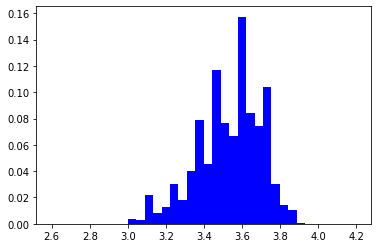

In [38]:
color_list = ['#000000','#e69f00','#56b4e9','#009e73','#f0e442', '#0072b2', '#d55e00', '#cc79a7'] # A color-blind friendly color scheme
labelsize = 10 # Control the size of labels on plots, to easily switch between presentation plots and article plots
titlesize = 16 # Control the size of titles on plots, to easily switch between presentation plots and article plots
histbins = 36 # A value to control binning of histograms. Should be an int because data is weighted
# 36 chosen to closely match 'fd' method on mdot observational data
hist2dalpha = 1 # A value to control the alphas (transparency) of the 2d histograms. Must be between 0 and 1.
hist2dbins = 25 # A value to control the number of 2D histogram bins. I tihnk it looks best with perfect squares, but can be any integer
markersizevalue = 2 # Set marker size in points
markspace = 10 # A value to control how many data points are plotted on evolution plots. Must be int or None (for all points to be plotted).
markspaceM = 10 # A value to control how many data points are plotted on evolution plots. Must be int or None (for all points to be plotted).
lumLimits = (2.6,4.2) # A value to control ranges of luminosity in plots. 2.6 to 4.2 is a good range for 0.7 to 2.0 solar mass agb stars
perLimits = (1.25,3.00) # A value to control ranges of pulsation period in plots. 1.25 to 3.00 fits all model and observational data used.
mDotLimits = (-7,-4) # A value to control ranges of plotted Mdot. Cannonical relation of dust-to-totla mdot leaves some oddly low mass loss. Relation likely not directly proportional.
MLimits = (0.4,2.2) # A value to control ranges of plotted masses. Not observable, so it just has to fit model and look nice.
TeffLimits = (3.2,3.8) # A value to control ranges of plotted effective T. 3.2 to 3.8 fits in all observational data.

pyplot.hist(LuminosityDataTrim, histbins,range=(lumLimits), weights=histWeight_trim, facecolor='b',histtype=u'stepfilled', label=(r'$\mathrm{Riebel\, et.\, al\, 2012}$'))

In [39]:
def calc_Bin_center(binedges):
    i = 0
    binCenters = []
    for i in range(0,len(binedges)-1):
        binCenter = (binedges[i]+binedges[i+1])/2
        binCenters.append(binCenter)
    return binCenters

[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.00455581 0.00379651 0.02581625
 0.00987092 0.01518603 0.03492787 0.02126044 0.03796507 0.08352316
 0.04100228 0.12224753 0.05694761 0.06529992 0.14654518 0.08352316
 0.07668945 0.11085801 0.03264996 0.01518603 0.01138952 0.0007593
 0.         0.         0.         0.         0.         0.        ]


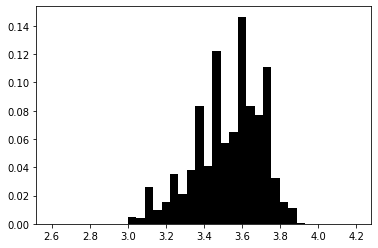

In [40]:
ObsvLCounts,ObsvLBinEdges, LHistplot=pyplot.hist(LuminosityDataNoCTrim, histbins,range=(lumLimits), weights=histWeight_absNoC_trim, stacked = True, color=color_list[0],histtype=u'stepfilled', label=(r'$\mathrm{M\, Stars}$',r'$\mathrm{C\, Stars}$'))
ObsvLBinCenters = calc_Bin_center(ObsvLBinEdges)
print(ObsvLCounts)

In [41]:
Polyfit=np.polyfit(ObsvLBinCenters,ObsvLCounts,10,full = True)
ObsvLCoeff = Polyfit[0]

In [42]:
Polyfit[1][0]

0.010728806128462233

In [43]:
def create_plottable_polynomial(coefficients,xarray): # Calculates the value p(x) for a polynomial given an array of coefficients and an array of x values to calculate at.
    function_values = [] # An array to hold all of the results p(x)
    for xindex in range(0, len(xarray)): # Increment over input x values to calculate the polynomial at each x. By using length of array 'xarray', the loop is adjusted dynamically based on input.
        #print('x position:',xindex)
        function_value_at_x = 0 # Reset the function value to reuse variable
        for coeff_index in range(0, len(coefficients)): # Increment over the coefficients array
            #print('Coefficient:',coefficients[coeff_index])
            function_value_at_x = function_value_at_x+coefficients[coeff_index]*xarray[xindex]**(len(coefficients)-1-coeff_index) #Calculate p(x) at the current value of xarray
        function_values.append(function_value_at_x) # Append the value of p(x) just found to an array of results
    return np.asarray(function_values)

In [44]:
ObsvLPolyFit=create_plottable_polynomial(ObsvLCoeff,ObsvLBinCenters)
print(ObsvLPolyFit)

[ 1.05886441e-03 -2.88899709e-03  6.28153794e-04  2.30841618e-03
  1.15944725e-03 -9.68744047e-04 -2.14323122e-03 -1.39163900e-03
  1.23358797e-03  5.04798722e-03  9.23595112e-03  1.32593019e-02
  1.70697002e-02  2.11115805e-02  2.61476962e-02  3.29763992e-02
  4.21243636e-02  5.35820080e-02  6.66572182e-02  7.99827008e-02
  9.16817514e-02  9.96906189e-02  1.02164592e-01  9.79225589e-02
  8.68137134e-02  6.99349595e-02  4.95972363e-02  2.89914040e-02
  1.15480004e-02  4.04668972e-05 -4.36565746e-03 -2.86180247e-03
  9.62640159e-04  2.45272648e-03 -4.92361374e-04 -2.67934985e-04]


(array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.        , 0.00455581,
        0.00379651, 0.02581625, 0.00987092, 0.01518603, 0.03492787,
        0.02126044, 0.03796507, 0.08352316, 0.04100228, 0.12224753,
        0.05694761, 0.06529992, 0.14654518, 0.08352316, 0.07668945,
        0.11085801, 0.03264996, 0.01518603, 0.01138952, 0.0007593 ,
        0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        ]),
 array([2.6       , 2.64444444, 2.68888889, 2.73333333, 2.77777778,
        2.82222222, 2.86666667, 2.91111111, 2.95555556, 3.        ,
        3.04444444, 3.08888889, 3.13333333, 3.17777778, 3.22222222,
        3.26666667, 3.31111111, 3.35555556, 3.4       , 3.44444444,
        3.48888889, 3.53333333, 3.57777778, 3.62222222, 3.66666667,
        3.71111111, 3.75555556, 3.8       , 3.84444444, 3.88888889,
        3.93333333, 3.97777778, 4.02222222, 4.06666667, 4.11111111,
        4.15555556, 4.2   

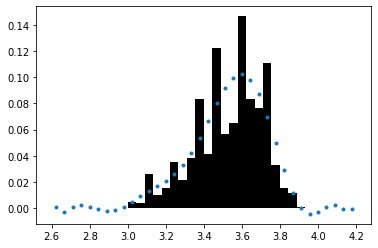

In [45]:
pyplot.plot(ObsvLBinCenters,ObsvLPolyFit,linestyle="None",marker=".")
pyplot.hist(LuminosityDataNoCTrim, histbins,range=(lumLimits), weights=histWeight_absNoC_trim, stacked = True, color=color_list[0],histtype=u'stepfilled', label=(r'$\mathrm{M\, Stars}$',r'$\mathrm{C\, Stars}$'))